In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas
import scipy

In [11]:
df = pandas.read_csv("../../results/ancestry/DGRP-3_ancestry.tsv", sep="\\s+")
arr = np.array(df)[:, 2:].astype(int)
p_afr = np.sum(arr == 1, axis=1) / np.sum(arr >= 0, axis=1)
chroms = list(df["chrom"])
positions = np.array(df["position"])

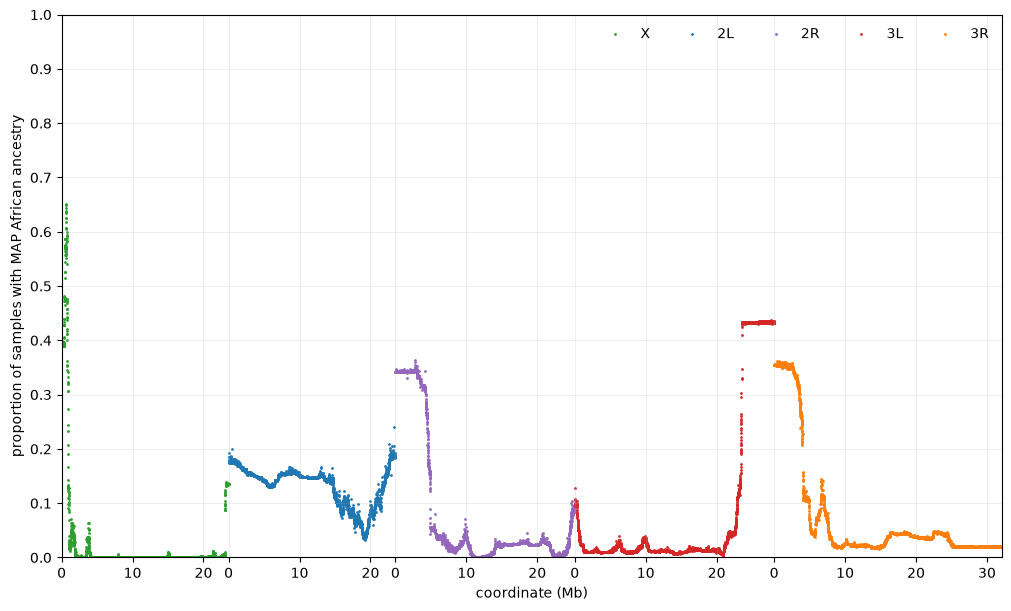

In [12]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6), layout="constrained")

colors = ["tab:green", "tab:blue", "tab:purple", "tab:red", "tab:orange"]
split_points = [0]
xticks = []
xtick_labels = []
for i, chrom in enumerate(["X", "2L", "2R", "3L", "3R"]):
    mask = np.array([c == chrom for c in chroms])
    xs = positions[mask] + split_points[-1]
    ys = p_afr[mask]
    plt.scatter(xs, ys, s=1, color=colors[i], label=chrom)
    _xticks = np.arange(0, positions[mask][-1], 10_000_000)
    xtick_labels += list(_xticks)
    xticks += list(_xticks + split_points[-1])
    split_points.append(xs[-1])

ax.legend(framealpha=0, ncols=5)
ax.set_ylim(0, 1)
ax.set_xlim(0, split_points[-1])
ax.grid(alpha=0.2)
# xticks = np.arange(0, 140_000_000, 10_000_000)
ax.set_xticks(xticks, (np.array(xtick_labels) / 1e6).astype(int))
ax.set_xlabel("coordinate (Mb)")
ax.set_yticks(np.linspace(0, 1, 11))
ax.set_ylabel("proportion of samples with MAP African ancestry")
plt.savefig("../../figures/African_ancestry_landscape_v2.png", dpi=244)
plt.savefig("../../figures/African_ancestry_landscape_v2.pdf")

In [10]:
def count_types(locusA, locusB):
    chromA, (startA, stopA) = locusA
    chromB, (startB, stopB) = locusB
    dfA = df[
        (df["chrom"] == chromA)
        & (df["position"] >= startA) 
        & (df["position"] <= stopA)]
    dfB = df[
        (df["chrom"] == chromB)
        & (df["position"] >= startB) 
        & (df["position"] <= stopB)]
    samples = list(df.columns[2:])
    comparisons = []
    type_counts = []
    p_fets = []
    for i, rowA in dfA.iterrows():
        for j, rowB in dfB.iterrows():
            siteA = f"{rowA['chrom']}:{rowA['position']}"
            siteB = f"{rowB['chrom']}:{rowB['position']}"
            comparisons.append((siteA, siteB))
            AA, AE, EA, EE = 0, 0, 0, 0
            for sample in samples:
                ancA = rowA[sample]
                ancB = rowB[sample]
                if ancA == 1 and ancB == 1:
                    AA += 1
                elif ancA == 1 and ancB == 0:
                    AE += 1
                elif ancA == 0 and ancB == 1:
                    EA += 1
                elif ancA == 0 and ancB == 0:
                    EE += 1
            type_counts_ij = [AA, AE, EA, EE]
            type_counts.append(type_counts_ij)
            table = np.reshape(type_counts_ij, (2, 2))
            p_fet = scipy.stats.fisher_exact(table, alternative="greater").pvalue
            p_fets.append(p_fet)
    for comp, counts, p_fet, in zip(comparisons, type_counts, p_fets):
        print(comp, counts, sum(counts), p_fet)
    
    return comparisons, type_counts

In [15]:
# Build 5: X:20,815,287..20,820,196 x 3L:4,416,058..4,419,369
# Build 6: X:20,944,260..20,949,169 x 3L:4,416,058..4,419,369
ret = count_types(
    ("X", (20_944_260, 20_949_169)),
    ("3L", (4_416_058, 4_419_369)),
)

('X:20944322', '3L:4416670') [0, 12, 35, 1056] 1103 1.0
('X:20944322', '3L:4417719') [0, 12, 35, 1054] 1101 1.0
('X:20944322', '3L:4418721') [0, 12, 36, 1056] 1104 1.0
('X:20945359', '3L:4416670') [0, 12, 35, 1055] 1102 1.0
('X:20945359', '3L:4417719') [0, 12, 35, 1053] 1100 1.0
('X:20945359', '3L:4418721') [0, 12, 36, 1055] 1103 1.0
('X:20946426', '3L:4416670') [0, 12, 35, 1057] 1104 1.0
('X:20946426', '3L:4417719') [0, 12, 35, 1055] 1102 1.0
('X:20946426', '3L:4418721') [0, 12, 36, 1057] 1105 1.0
('X:20947514', '3L:4416670') [0, 13, 35, 1051] 1099 1.0
('X:20947514', '3L:4417719') [0, 13, 35, 1049] 1097 1.0
('X:20947514', '3L:4418721') [0, 13, 36, 1051] 1100 1.0
('X:20948754', '3L:4416670') [0, 12, 35, 1057] 1104 1.0
('X:20948754', '3L:4417719') [0, 12, 35, 1055] 1102 1.0
('X:20948754', '3L:4418721') [0, 12, 36, 1057] 1105 1.0


In [17]:
# Build 5: 2R:11,353,691..11,359,516 x 3L:11,079,088..11,085,304
# Build 6: 2R:15,466,186..15,472,011 x 3L:11,085,988..11,092,204

ret = count_types(
    ("2R", (15_466_186, 15_472_011)),
    ("3L", (11_085_988, 11_092_204)),
)

('2R:15466873', '3L:11086974') [9, 105, 78, 733] 925 0.7722350029128726
('2R:15466873', '3L:11088860') [9, 105, 80, 732] 926 0.7947752591306899
('2R:15466873', '3L:11089884') [9, 105, 80, 732] 926 0.7947752591306899
('2R:15466873', '3L:11090917') [9, 105, 80, 733] 927 0.7936587286286332
('2R:15466873', '3L:11092039') [9, 105, 79, 733] 926 0.7831457785081424
('2R:15467875', '3L:11086974') [9, 105, 78, 733] 925 0.7722350029128726
('2R:15467875', '3L:11088860') [9, 105, 80, 732] 926 0.7947752591306899
('2R:15467875', '3L:11089884') [9, 105, 80, 732] 926 0.7947752591306899
('2R:15467875', '3L:11090917') [9, 105, 80, 733] 927 0.7936587286286332
('2R:15467875', '3L:11092039') [9, 105, 79, 733] 926 0.7831457785081424
('2R:15468978', '3L:11086974') [9, 105, 79, 733] 926 0.7831457785081424
('2R:15468978', '3L:11088860') [9, 105, 81, 732] 927 0.8048653866307597
('2R:15468978', '3L:11089884') [9, 105, 81, 732] 927 0.8048653866307597
('2R:15468978', '3L:11090917') [9, 105, 81, 733] 928 0.803778534

In [13]:
ret = count_types(
    ("X", (2_000_000, 2_005_000)),
    ("X", (18_500_000, 18_505_000)),
)

('X:2000937', 'X:18500526') [0, 169, 1, 984] 1154 1.0
('X:2000937', 'X:18501937') [0, 169, 1, 985] 1155 1.0
('X:2000937', 'X:18503242') [0, 169, 1, 985] 1155 1.0
('X:2000937', 'X:18504304') [0, 169, 1, 986] 1156 1.0
('X:2002245', 'X:18500526') [0, 190, 1, 976] 1167 1.0
('X:2002245', 'X:18501937') [0, 190, 1, 977] 1168 1.0
('X:2002245', 'X:18503242') [0, 190, 1, 977] 1168 1.0
('X:2002245', 'X:18504304') [0, 190, 1, 978] 1169 1.0
('X:2003573', 'X:18500526') [0, 191, 1, 976] 1168 1.0
('X:2003573', 'X:18501937') [0, 191, 1, 977] 1169 1.0
('X:2003573', 'X:18503242') [0, 191, 1, 977] 1169 1.0
('X:2003573', 'X:18504304') [0, 191, 1, 978] 1170 1.0


In [14]:
ret = count_types(
    ("2L", (10_000_000, 10_005_000)),
    ("2L", (11_000_000, 11_005_000)),
)

('2L:10000732', '2L:11000297') [138, 2, 9, 798] 947 3.02983799436542e-152
('2L:10000732', '2L:11001308') [138, 2, 8, 798] 946 2.1767733189710867e-153
('2L:10000732', '2L:11002344') [138, 2, 8, 798] 946 2.1767733189710867e-153
('2L:10000732', '2L:11003360') [138, 2, 9, 798] 947 3.02983799436542e-152
('2L:10000732', '2L:11004415') [138, 2, 8, 798] 946 2.1767733189710867e-153
('2L:10001800', '2L:11000297') [138, 2, 9, 798] 947 3.02983799436542e-152
('2L:10001800', '2L:11001308') [138, 2, 8, 798] 946 2.1767733189710867e-153
('2L:10001800', '2L:11002344') [138, 2, 8, 798] 946 2.1767733189710867e-153
('2L:10001800', '2L:11003360') [138, 2, 9, 798] 947 3.02983799436542e-152
('2L:10001800', '2L:11004415') [138, 2, 8, 798] 946 2.1767733189710867e-153
('2L:10002819', '2L:11000297') [138, 2, 9, 798] 947 3.02983799436542e-152
('2L:10002819', '2L:11001308') [138, 2, 8, 798] 946 2.1767733189710867e-153
('2L:10002819', '2L:11002344') [138, 2, 8, 798] 946 2.1767733189710867e-153
('2L:10002819', '2L:11